# 30 · Supervisor and hand-offs: specialists in one graph
Level L5 · Part 5 · professional · ~35 min · builds on 29, 14

## Goal
Build a supervisor graph with two specialists: an orders agent and a policy agent. The supervisor reads the state, decides who works next, and
hands over. Each specialist does its part and returns control with `Command`, which names the next node and the state it leaves. The run stops
when every part has an answer. The hand-offs are edges you can draw and read.

## Why it matters
In lesson 29 a router sent each part to one specialist and stopped. Real questions need more back-and-forth: the policy answer depends on the
order's status, or a specialist finds it needs another. A supervisor makes the order of work explicit, and every hand-off is a recorded step.
Without it, the specialists call each other in a loop, and nobody can say who decided what.

| A router, one hop | A supervisor with hand-offs |
|---|---|
| One specialist per question | Several hops, decided step by step |
| The router's decision is final | The supervisor can send work back, or finish |
| The path is invisible | Each hand-off is a saved step with a sender and a receiver |

## The idea
A **supervisor** is a node that decides the next step from the state. A **hand-off** is `Command(goto=...)` from a specialist: it names the next
node and updates the state. Control always returns through the supervisor, so one node knows the whole path. A **guard** on the number of hops
ends the run if the supervisor keeps sending work around (lesson 31 covers guards in depth).

## Picture
The diagram is drawn by `show_mermaid`, a course helper in `graph_view.py` that renders a Mermaid text diagram in the notebook. Read the arrows:
every specialist returns to the supervisor, and only the supervisor ends the run.

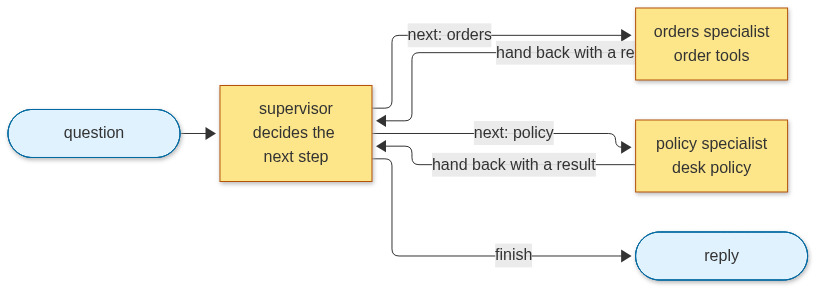

In [1]:
import sys; sys.path.insert(0, "../../..")  # the topic folder: llm_setup.py, graph_view.py and tut_env.py live there

from graph_view import show_mermaid

show_mermaid("""
flowchart LR
  U(["question"]) --> S["supervisor<br/>decides the next step"]
  S -->|next: orders| O["orders specialist<br/>order tools"]
  S -->|next: policy| P["policy specialist<br/>desk policy"]
  S -->|finish| E(["reply"])
  O -->|hand back with a result| S
  P -->|hand back with a result| S
  classDef model fill:#fde68a,stroke:#b45309
  classDef code fill:#e0f2fe,stroke:#0369a1
  class S,O,P model
  class U,E code
""")

## Step by step
Four steps. Steps 1 to 3 make no model call. Step 4 is the one run that calls the model, five times in all.

**Step 1 · the tools and the state (no call).** The orders tool is the lookup from lesson 29; it reads the course's sample desk data
(`support_eval.json`, introduced in lesson 07). The state holds the question, the results each specialist adds, and the number of hand-offs.
`MAX_HOPS` is the guard: the run stops after four hand-offs, whatever the supervisor decides.

In [2]:
import json
import operator
from pathlib import Path
from typing import Annotated, Literal

from langchain_core.tools import tool
from pydantic import BaseModel, ConfigDict, Field
from typing_extensions import TypedDict

ORDERS = json.loads((Path("../../../data") / "support_eval.json").read_text())["world"]["orders"]
MAX_HOPS = 4  # the guard: at most four hand-offs in one run


class OrderQuery(BaseModel):
    model_config = ConfigDict(extra="forbid")
    order_id: str = Field(description="The order number the customer wrote: four digits, such as 1003.", pattern=r"^\d{4}$")


@tool(args_schema=OrderQuery)
def order_status(order_id: str) -> dict:
    """Look up one order's status and days late."""
    return ORDERS.get(order_id, {"error": f"no order {order_id}"})

The state and the two parts of the question come next. Each specialist answers only its own part.

In [3]:
class DeskState(TypedDict):
    question: str
    results: Annotated[list, operator.add]  # each specialist adds what it found
    hops: int
    reply: str


POLICY = "After 10 working days from dispatch, contact the desk; we trace the parcel or send a replacement or refund."
PARTS = {"orders": "What is the status of order 1003?",
         "policy": "What does the policy say about lost parcels?"}

**Step 2 · the specialists and the supervisor (no call yet).** `llm_replay` is a course helper that records each model answer the first time
and replays it offline, so the lesson runs with no key. `get_llm` is the course helper that sets up the course model (Gemini on Vertex AI,
configured in `.env`). Each specialist is an agent: the orders agent has the lookup tool, and the policy agent has the desk policy in its
instructions. The supervisor's decider returns one structured answer: which part is next.

In [4]:
import llm_replay

llm_replay.start("30_supervisor-and-handoffs")

from langchain.agents import create_agent
from langchain_core.messages import HumanMessage
from llm_setup import get_llm
from langgraph.graph import END, START, StateGraph
from langgraph.types import Command
from graph_view import show_graph

llm = get_llm()


class Decision(BaseModel):
    next: Literal["orders", "policy"]


decider = llm.with_structured_output(Decision)
orders_agent = create_agent(model=llm, tools=[order_status], system_prompt="Answer order facts with the tool only.")
policy_agent = create_agent(model=llm, tools=[], system_prompt=f"Answer policy questions from this policy only: {POLICY}")

LLM mode: replay (30_supervisor-and-handoffs.yaml)


Gemini on Vertex AI · API key loaded: True


The supervisor is a plain function. It checks the guard first, then the finish, and only then asks the model which part is next. The finish is
a check on the state, not a model decision: the run ends only when every part has a result.

In [5]:
def supervisor(state: DeskState) -> Command:
    if state["hops"] >= MAX_HOPS:  # the guard runs before any model call
        return Command(goto=END, update={"reply": "Stopped: too many hand-offs. A person will follow up."})
    done = {r["by"] for r in state["results"]}
    if set(PARTS) <= done:  # finish only when every part has a result
        return Command(goto=END, update={"reply": " ".join(r["text"] for r in state["results"])})
    todo = [p for p in PARTS if p not in done]
    decision = decider.invoke(
        f"Question: {state['question']}\nAlready answered: {sorted(done) or 'nothing'}. Still to do: {todo}.\n"
        "Reply with one part from 'still to do'.")
    nxt = decision.next if decision.next in todo else todo[0]  # never hand work back to a part already answered
    return Command(goto=nxt, update={"hops": state["hops"] + 1})

The two specialists return control to the supervisor with their result. Then the graph is wired: the supervisor is the only node that can end it.

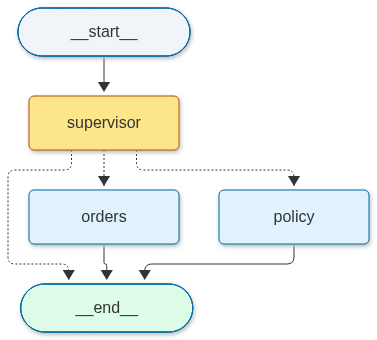

In [6]:
def orders_specialist(state: DeskState) -> Command:
    out = orders_agent.invoke({"messages": [HumanMessage(content=PARTS["orders"])]}, config={"recursion_limit": 4})
    return Command(goto="supervisor", update={"results": [{"by": "orders", "text": out["messages"][-1].text}]})


def policy_specialist(state: DeskState) -> Command:
    out = policy_agent.invoke({"messages": [HumanMessage(content=PARTS["policy"])]}, config={"recursion_limit": 4})
    return Command(goto="supervisor", update={"results": [{"by": "policy", "text": out["messages"][-1].text}]})


g = StateGraph(DeskState)
g.add_node("supervisor", supervisor, destinations=("orders", "policy", END))
g.add_node("orders", orders_specialist)
g.add_node("policy", policy_specialist)
g.add_edge(START, "supervisor")
desk = g.compile()
show_graph(desk, model_nodes=("supervisor",))

**Step 3 · the guard, no model call.** The guard is checked before the model is asked. Here the supervisor is handed a state that has already
used four hand-offs, so it stops at once: the `reply` line is what the caller receives, and the model is never called.

In [7]:
stopped = supervisor({"question": "Order 1003 never arrived.", "results": [], "hops": MAX_HOPS, "reply": ""})
print("goto:", stopped.goto)
print("reply:", stopped.update["reply"])

goto: __end__
reply: Stopped: too many hand-offs. A person will follow up.


**Step 4 · run a question that needs both specialists (5 model calls).** The supervisor sends the question to the orders specialist, takes the
result back, sends the policy part to the policy specialist, and then finishes. The calls are: two supervisor decisions, two for the orders
specialist (the tool call and its answer), and one for the policy specialist. Every hand-off is a step in the saved path.

In [8]:
final = desk.invoke({"question": "Order 1003 never arrived. What is its status, and what does the policy say about lost parcels?",
                     "results": [], "hops": 0, "reply": ""}, config={"recursion_limit": 20})
for r in final["results"]:
    print(f"{r['by']:>8}: {r['text'][:120]}")
print("reply:", final["reply"][:200])
print("hand-offs:", final["hops"])
llm_replay.stop()  # the last model call of this lesson

  orders: The status of order 1003 is "lost," and it is 9 days late.
  policy: If your parcel has not arrived, please wait until 10 working days have passed from the date of dispatch. After this peri
reply: The status of order 1003 is "lost," and it is 9 days late. If your parcel has not arrived, please wait until 10 working days have passed from the date of dispatch. After this period, you should contac
hand-offs: 2


## At work
- A supervisor is the one place that knows the whole path. Teams log each hand-off with the sender, the receiver and the state it passed →
  lesson 33 (observability).
- A hand-off that passes the whole conversation costs tokens on every hop. Teams pass only the state each specialist needs → lesson 36 (cost).
- The guard is not optional. A supervisor that can loop will loop, and the run must end with a reply, not a timeout → lesson 31 (failure modes).

## What just happened
- The supervisor sent the question to the orders specialist first, then to the policy specialist: two hand-offs, so the printed `hand-offs` is 2.
- Each result has a sender: `orders` and `policy` each appear once in the printed results.
- The reply joins the two answers, and the run ends after the second result: the supervisor finishes without a third hand-off.
- The run took five model calls in total, the budget this lesson keeps to.

## Common mistakes
1. **Specialists that call each other.** Then no one knows the path. Hand-offs go back through the supervisor. Here two agents hand work to each
   other with no supervisor; the runtime stops the loop with an error, and the path is never written down.

In [9]:
from langgraph.graph import START, StateGraph
from langgraph.types import Command
from typing_extensions import TypedDict


class Ping(TypedDict):
    turns: int


def agent_a(state: Ping) -> Command:
    return Command(goto="agent_b", update={"turns": state["turns"] + 1})


def agent_b(state: Ping) -> Command:
    return Command(goto="agent_a", update={"turns": state["turns"] + 1})


loop = StateGraph(Ping)
loop.add_node("agent_a", agent_a, destinations=("agent_b",))
loop.add_node("agent_b", agent_b, destinations=("agent_a",))
loop.add_edge(START, "agent_a")
loop = loop.compile()
try:
    loop.invoke({"turns": 0}, config={"recursion_limit": 10})
except Exception as err:
    print(type(err).__name__, "-", str(err).splitlines()[0])

GraphRecursionError - Recursion limit of 10 reached without hitting a stop condition. You can increase the limit by setting the `recursion_limit` config key.


2. **No hop limit.** The supervisor can send work around forever. Without the guard, the only stop is the runtime's recursion limit: the error
   printed above is what the caller gets, and there is no reply. The guard in Step 3 writes a reply instead, so the caller always gets an answer.

3. **A finish with no check.** Writing the reply from a part that has no result fails. The supervisor checks `set(PARTS) <= done` before it
   finishes, so a missing part is never read. The check below shows the failure it prevents.

In [10]:
answers = {"orders": "Order 1003 is 2 days late."}  # the policy result is missing
try:
    print(answers["policy"])
except KeyError as err:
    print(type(err).__name__, "-", str(err))

KeyError - 'policy'


## Production checklist
Before a supervisor graph goes to real users, check these:
- Every hand-off is logged with its sender, receiver and the state it passed, so a bad answer can be traced to one step → lesson 33.
- The hop limit is tested: a run that reaches it ends with a reply, and the reply is logged as a stop, not a success → lesson 31.
- Each specialist gets only the state it needs, and the same fixed questions are run after every prompt change → lesson 32 (evals in CI).

## Try it
Write `ready_to_finish(question_parts, results)` that returns `True` when every name in `question_parts` appears as a `by` value in `results`, and
`False` otherwise. Test it on `["orders", "policy"]` with results from `orders` only, and then with results from both. No model call is needed.

In [11]:
# your code here

**Answer** — try it first, then expand the hidden cell below.

In [12]:
def ready_to_finish(question_parts: list[str], results: list[dict]) -> bool:
    done = {r["by"] for r in results}
    return all(part in done for part in question_parts)


print(ready_to_finish(["orders", "policy"], [{"by": "orders"}]),
      ready_to_finish(["orders", "policy"], [{"by": "orders"}, {"by": "policy"}]))  # False True

False True


## Key terms
- **Supervisor** — the node that decides the next step from the state; control always returns to it.
- **Specialist** — an agent that does one part of the question, with its own tools or instructions.
- **Hand-off** — `Command(goto=..., update=...)`: a move to the next node, carrying the state it passes on.
- **Guard (hop limit)** — a counter that ends the run with a reply when too many hand-offs have happened.

## Recap
- A supervisor decides the next step from the state; control always comes back to it.
- A hand-off is `Command(goto=..., update=...)`: it names the next node and what it passes on.
- A hop limit ends the run with a reply, and a finish is allowed only when every part has a result.

**Interview:** "How would you coordinate two specialist agents for one customer question?" Strong answer: "A supervisor graph decides each step from the
state. Specialists return control to it with their result, so one node sees the path. I cap the hand-offs, and I finish only when every part is answered."